# Cài đặt và Import thư viện

In [6]:
import joblib
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mô hình
import lightgbm as lgb
import xgboost as xgb

# Đánh giá
from sklearn.metrics import (
    classification_report, 
    f1_score, 
    recall_score, 
    precision_score, 
    roc_auc_score, 
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# Đường dẫn đến thư mục chứa dữ liệu đã xử lý
DATA_PATH = r'C:\Users\Acer\OneDrive - National Economics University\Desktop\machine learning\data\processed'

# 1. Load dữ liệu đã tiền xử lý

In [7]:
def load_data(path):
    X_train = joblib.load(os.path.join(path, 'X_train_res.pkl'))
    y_train = joblib.load(os.path.join(path, 'y_train_res.pkl'))
    X_test = joblib.load(os.path.join(path, 'X_test.pkl'))
    y_test = joblib.load(os.path.join(path, 'y_test.pkl'))
    feature_cols = joblib.load(os.path.join(path, 'feature_cols.pkl'))
    return X_train, y_train, X_test, y_test, feature_cols

X_train, y_train, X_test, y_test, feature_cols = load_data(DATA_PATH)
print(f"Dữ liệu huấn luyện (đã SMOTE): {X_train.shape}")
print(f"Dữ liệu kiểm tra: {X_test.shape}")

Dữ liệu huấn luyện (đã SMOTE): (516773, 28)
Dữ liệu kiểm tra: (118929, 28)


# 2. LightGBM training

In [8]:
print("\n--- Đang huấn luyện LightGBM ---")
lgb_model = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)
lgb_model.fit(X_train, y_train)


--- Đang huấn luyện LightGBM ---


LGBMClassifier(learning_rate=0.05, n_estimators=1000, n_jobs=-1,
               random_state=42, verbose=-1)

## 3. XGBoost training

In [9]:
print("--- Đang huấn luyện XGBoost ---")
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    n_jobs=-1,
    tree_method='hist' # Tối ưu tốc độ
)
xgb_model.fit(X_train, y_train)

--- Đang huấn luyện XGBoost ---


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=-1, num_parallel_tree=None, ...)

# 4. Evaluation Metrics

In [14]:
# Dự đoán với LightGBM
lgb_preds = lgb_model.predict(X_test)
lgb_probs = lgb_model.predict_proba(X_test)[:, 1]

# Dự đoán với XGBoost
xgb_preds = xgb_model.predict(X_test)
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]

# Hàm tính toán chỉ số
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        "F1": f1_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "AUC-PR": average_precision_score(y_true, y_prob)
    }

# Tính toán
lgb_metrics = calculate_metrics(y_test, lgb_preds, lgb_probs)
xgb_metrics = calculate_metrics(y_test, xgb_preds, xgb_probs)

# In kết quả ra màn hình
comparison_df = pd.DataFrame([lgb_metrics, xgb_metrics], index=['LightGBM', 'XGBoost'])
print("\nBảng so sánh hiệu năng:")
display(comparison_df)

c:\Users\Acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\Acer\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Bảng so sánh hiệu năng:


,F1,Recall,Precision,AUC-PR
LightGBM,0.833611,0.782813,0.891459,0.933470
XGBoost,0.831873,0.778906,0.892569,0.932269


# 5. Visualization

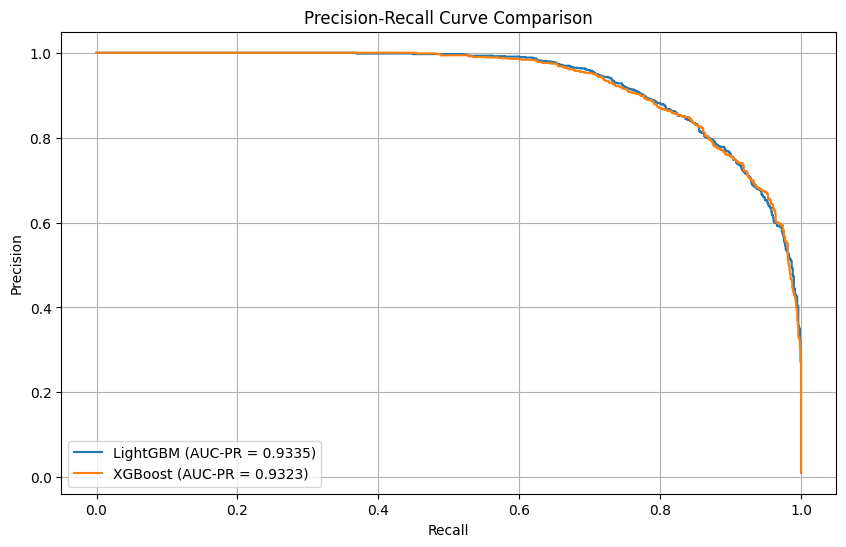

In [13]:
# Vẽ biểu đồ Precision-Recall Curve
plt.figure(figsize=(10, 6))

for model_name, probs in zip(['LightGBM', 'XGBoost'], [lgb_probs, xgb_probs]):
    precision, recall, _ = precision_recall_curve(y_test, probs)
    auc_pr = average_precision_score(y_test, probs)
    plt.plot(recall, precision, label=f'{model_name} (AUC-PR = {auc_pr:.4f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid(True)
plt.show()